# code_169 · Clipped policy updates and entropy-regularized actuation

**Book:** section 32.3. Restart and run all cells. All imports, helpers and generated inputs are internal. Ordinary execution requires no files, network, credentials or GPU. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_32_GUIDE.md), [execution evidence](../CHAPTER_32_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_169).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, Torch 2.14.1 CPU. Allow two minutes to run and 45–90 minutes to interpret. Original small implementations expose actual updates and controls; they are not benchmark reproductions or operational controllers. Rewards, transitions, observation boundaries and independent assessment are defined below. Simulated rewards do not establish field safety or causal identification from arbitrary logs.


In [1]:
import platform,time,json,copy,hashlib,itertools
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
import torch
from torch import nn
START=time.perf_counter();SEED=5369;rng=np.random.default_rng(SEED)
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__,'torch':torch.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0', 'torch': '2.14.1'}
CPU: Darwin arm64 seed: 5369


<a id="ppo-maintenance-policy"></a>
 ## Train a discrete maintenance actor from fresh trajectories
 Each of thirty batches collects 48 independent episodes of 12 decisions, starting healthy. Waiting earns 1/0.2/−4 by condition; repair costs 1.2 and resets condition. Waiting deteriorates with probabilities 0.2/0.3. The observation includes a one-hot condition and remaining time, so the natural finite-horizon termination is represented. The actor and critic each have one 16-unit tanh hidden layer. Frozen action probabilities and returns define each PPO batch; four full-batch epochs maximize the clipped ratio objective(0.2), with entropy coefficient 0.01 and critic loss coefficient 0.5. No replay or future evaluation outcomes enter PPO fitting. Monte Carlo returns use discount 0.95 and zero value at the true horizon. We evaluate the final actor's deterministic argmax, not its training-time stochastic exploration policy.


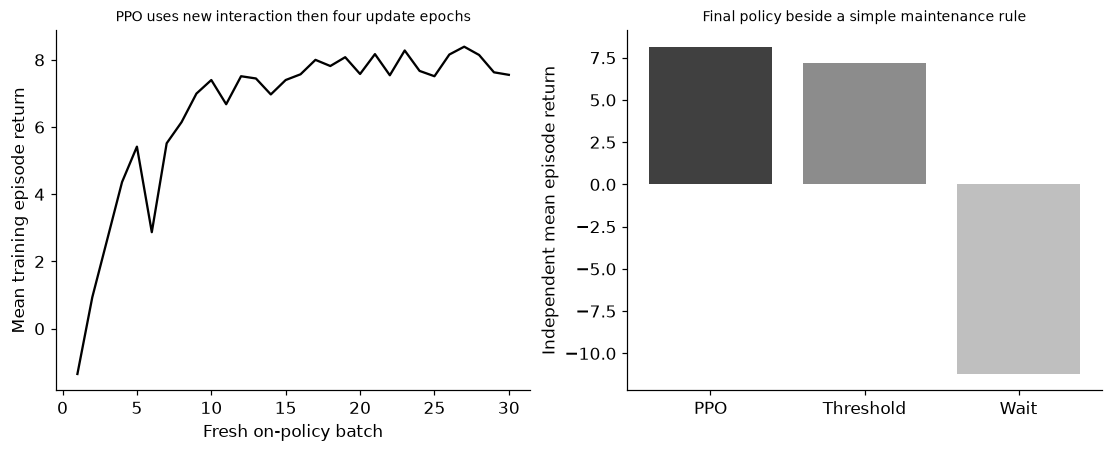

In [2]:
H=12;B=48;actor=nn.Sequential(nn.Linear(4,16),nn.Tanh(),nn.Linear(16,2));critic=nn.Sequential(nn.Linear(4,16),nn.Tanh(),nn.Linear(16,1));optimizer=torch.optim.Adam(list(actor.parameters())+list(critic.parameters()),lr=.01);ppo_curve=[];clip_fractions=[]
for batch in range(30):
    state=np.zeros(B,int);obs_list=[];act_list=[];log_list=[];rew_list=[];val_list=[]
    for t in range(H):
        obs=torch.tensor(np.column_stack([np.eye(3)[state],np.full(B,(H-t)/H)]))
        with torch.no_grad():dist=torch.distributions.Categorical(logits=actor(obs));a=dist.sample();log=dist.log_prob(a);v=critic(obs).squeeze(1)
        aa=a.numpy();reward=np.where(aa==1,-1.2,np.array([1.,.2,-4.])[state]);deteriorate=rng.random(B)<np.where(state==0,.2,.3);state=np.where(aa==1,0,np.minimum(2,state+deteriorate));obs_list.append(obs);act_list.append(a);log_list.append(log);rew_list.append(reward);val_list.append(v)
    returns=np.zeros((H,B));g=np.zeros(B)
    for t in reversed(range(H)):g=rew_list[t]+.95*g;returns[t]=g
    obs=torch.cat(obs_list);acts=torch.cat(act_list);oldlog=torch.cat(log_list);ret=torch.tensor(returns.reshape(-1));adv=ret-torch.cat(val_list);adv=(adv-adv.mean())/(adv.std()+1e-8)
    for epoch in range(4):
        dist=torch.distributions.Categorical(logits=actor(obs));ratio=(dist.log_prob(acts)-oldlog).exp();surrogate=torch.minimum(ratio*adv,ratio.clamp(.8,1.2)*adv);loss=-surrogate.mean()-.01*dist.entropy().mean()+.5*nn.functional.mse_loss(critic(obs).squeeze(1),ret);optimizer.zero_grad();loss.backward();nn.utils.clip_grad_norm_(list(actor.parameters())+list(critic.parameters()),1.);optimizer.step()
    ppo_curve.append(float(np.sum(rew_list,axis=0).mean()));clip_fractions.append(float(((ratio.detach()-1).abs()>.2).double().mean()))
def evaluate_discrete(mode):
    gr=np.random.default_rng(SEED+100);state=np.zeros(300,int);total=np.zeros(300);discounted=np.zeros(300)
    for t in range(H):
        if mode=='PPO':
            with torch.no_grad():a=actor(torch.tensor(np.column_stack([np.eye(3)[state],np.full(300,(H-t)/H)]))).argmax(1).numpy()
        elif mode=='Threshold':a=(state==2).astype(int)
        else:a=np.zeros(300,int)
        reward=np.where(a==1,-1.2,np.array([1.,.2,-4.])[state]);total+=reward;discounted+=(.95**t)*reward;u=gr.random(300);state=np.where(a==1,0,np.minimum(2,state+(u<np.where(state==0,.2,.3))))
    return {'mean_undiscounted_return':float(total.mean()),'mean_discounted_return':float(discounted.mean()),'episode_SD':float(total.std(ddof=1))}
discrete={k:evaluate_discrete(k) for k in ['PPO','Threshold','Always wait']};assert len(ppo_curve)==30 and torch.isfinite(ratio).all() and ret.numel()==H*B
RESULTS.update(PPO={'training_episodes':30*B,'interaction_steps':30*B*H,'epochs_per_batch':4,'clip_epsilon':.2,'entropy_coefficient':.01,'critic_loss_coefficient':.5,'discount':.95,'final_batch_clip_fraction':clip_fractions[-1],'final_evaluation_episodes_per_policy':300,'evaluation_policy':'deterministic argmax','evaluation':discrete})
fig,axes=plt.subplots(1,2,figsize=(10,4));axes[0].plot(np.arange(1,31),ppo_curve,color='black');axes[0].set(xlabel='Fresh on-policy batch',ylabel='Mean training episode return',title='PPO uses new interaction then four update epochs');axes[1].bar(range(3),[v['mean_undiscounted_return'] for v in discrete.values()],color=['.25','.55','.75']);axes[1].set(xticks=range(3),xticklabels=['PPO','Threshold','Wait'],ylabel='Independent mean episode return',title='Final policy beside a simple maintenance rule');plt.show()


<a id="sac-continuous-actuator"></a>
 ## Train a continuous stochastic actor with a real replay buffer
 The distinct actuator simulator evolves x'=0.85 x+0.5 a+noise, clipped to[−2,2], with bounded action a∈[−1,1] and reward−x²−0.05 a². SAC uses a tanh-Gaussian actor with its change-of-variables log-density correction, two independent 32-unit critics, minimum target Q, Polyak target updates 0.005, fixed entropy temperature 0.1 and off-policy replay. A 32-step external reset is a truncation of this continuing task: every target bootstraps from the actual next state, including the last record before reset. Collect 3,600 steps,256 uniform warm-up actions, then one 64-record update per step. Compare deterministic actor means against zero action and clipped proportional control on sixty independent 32-step noise trajectories. The PPO and SAC bars solve different tasks and cannot rank algorithms against one another.


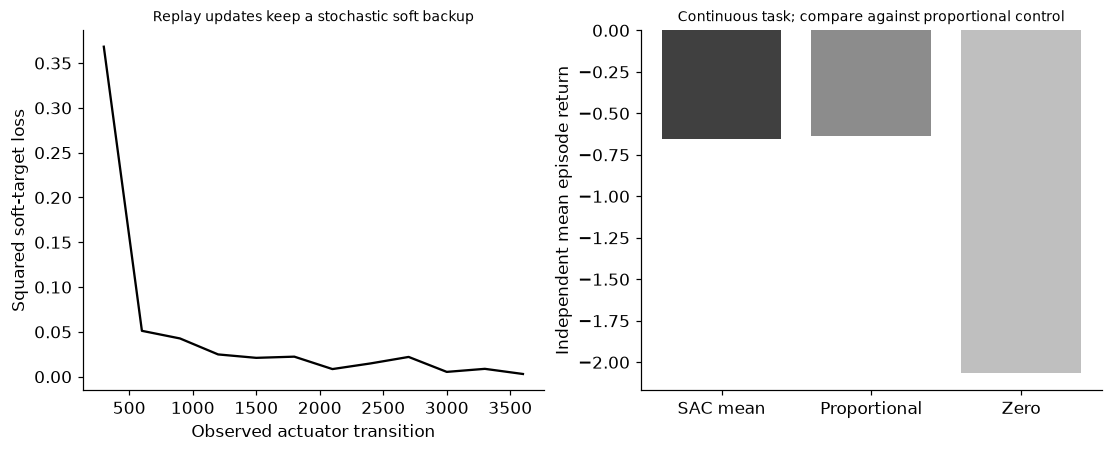

In [3]:
class GaussianActor(nn.Module):
    def __init__(self):super().__init__();self.net=nn.Sequential(nn.Linear(1,32),nn.Tanh(),nn.Linear(32,2))
    def sample(self,x,deterministic=False):
        mean,logstd=self.net(x).chunk(2,1);logstd=logstd.clamp(-4,1);normal=torch.distributions.Normal(mean,logstd.exp());z=mean if deterministic else normal.rsample();a=torch.tanh(z);logp=(normal.log_prob(z)-torch.log(1-a.square()+1e-6)).sum(1,keepdim=True);return a,logp
def qnet():return nn.Sequential(nn.Linear(2,32),nn.Tanh(),nn.Linear(32,1))
policy=GaussianActor();q1=qnet();q2=qnet();t1=copy.deepcopy(q1);t2=copy.deepcopy(q2);qo=torch.optim.Adam(list(q1.parameters())+list(q2.parameters()),lr=.003);po=torch.optim.Adam(policy.parameters(),lr=.001);buffer=[];state=float(rng.uniform(-1,1));sac_trace=[];updates=0
for step in range(3600):
    if step<256:action=float(rng.uniform(-1,1))
    else:
        with torch.no_grad():action=float(policy.sample(torch.tensor([[state]]))[0][0,0])
    ns=float(np.clip(.85*state+.5*action+rng.normal(0,.08),-2,2));reward=-state**2-.05*action**2;buffer.append((state,action,reward,ns));state=float(rng.uniform(-1,1)) if (step+1)%32==0 else ns
    if step<256:continue
    batch=np.array([buffer[i] for i in rng.integers(0,len(buffer),64)]);x=torch.tensor(batch[:,0:1]);a=torch.tensor(batch[:,1:2]);rr=torch.tensor(batch[:,2:3]);nx=torch.tensor(batch[:,3:4])
    with torch.no_grad():na,nlp=policy.sample(nx);target=rr+.95*(torch.minimum(t1(torch.cat([nx,na],1)),t2(torch.cat([nx,na],1)))-.1*nlp)
    critic_loss=nn.functional.mse_loss(q1(torch.cat([x,a],1)),target)+nn.functional.mse_loss(q2(torch.cat([x,a],1)),target);qo.zero_grad();critic_loss.backward();qo.step()
    for q in [q1,q2]:q.requires_grad_(False)
    pa,lp=policy.sample(x);policy_loss=(.1*lp-torch.minimum(q1(torch.cat([x,pa],1)),q2(torch.cat([x,pa],1)))).mean();po.zero_grad();policy_loss.backward();po.step()
    for q in [q1,q2]:q.requires_grad_(True)
    with torch.no_grad():
        for source,target_net in [(q1,t1),(q2,t2)]:
            for p,tp in zip(source.parameters(),target_net.parameters()):tp.mul_(.995).add_(p,alpha=.005)
    updates+=1
    if (step+1)%300==0:sac_trace.append((step+1,float(critic_loss.detach()),float(policy_loss.detach())))
def evaluate_actuator(mode):
    gr=np.random.default_rng(SEED+200);state=gr.uniform(-1,1,60);total=np.zeros(60);discounted=np.zeros(60)
    for t in range(32):
        if mode=='SAC mean':
            with torch.no_grad():a=policy.sample(torch.tensor(state[:,None]),True)[0][:,0].numpy()
        elif mode=='Proportional':a=np.clip(-1.7*state,-1,1)
        else:a=np.zeros(60)
        reward=-state**2-.05*a**2;total+=reward;discounted+=(.95**t)*reward;state=np.clip(.85*state+.5*a+gr.normal(0,.08,60),-2,2)
    return {'mean_undiscounted_return':float(total.mean()),'mean_discounted_return':float(discounted.mean()),'episode_SD':float(total.std(ddof=1))}
continuous={k:evaluate_actuator(k) for k in ['SAC mean','Proportional','Zero action']};assert updates==3344 and len(buffer)==3600 and np.isfinite(sac_trace).all()
with torch.no_grad():test_a,test_lp=policy.sample(torch.linspace(-2,2,100)[:,None]);assert torch.isfinite(test_lp).all() and test_a.abs().max()<=1
RESULTS.update(SAC={'interaction_steps':3600,'uniform_warmup_steps':256,'updates':updates,'batch_size':64,'replay_records':len(buffer),'temperature':.1,'target_polyak':.005,'discount':.95,'external_reset_period':32,'bootstrap_at_external_reset':True,'final_evaluation_episodes_per_policy':60,'evaluation_policy':'deterministic tanh mean','evaluation':continuous})
fig,axes=plt.subplots(1,2,figsize=(10,4));st=np.array(sac_trace);axes[0].plot(st[:,0],st[:,1],color='black',label='Twin critic loss');axes[0].set(xlabel='Observed actuator transition',ylabel='Squared soft-target loss',title='Replay updates keep a stochastic soft backup');axes[1].bar(range(3),[v['mean_undiscounted_return'] for v in continuous.values()],color=['.25','.55','.75']);axes[1].set(xticks=range(3),xticklabels=['SAC mean','Proportional','Zero'],ylabel='Independent mean episode return',title='Continuous task; compare against proportional control');plt.show()


In [4]:
summary={'example_id':'code_169','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual stochastic on-policy PPO with frozen behavior probabilities and clipped surrogate', 'finite-horizon observed clock and Monte Carlo advantage critic', 'actual continuous tanh-Gaussian SAC with corrected log density twin critics replay and target updates', 'separate independent simulator evaluation and simple controls', 'training budgets and distinct-task interpretation limits'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual stochastic on-policy PPO with frozen behavior probabilities and clipped surrogate", "finite-horizon observed clock and Monte Carlo advantage critic", "actual continuous tanh-Gaussian SAC with corrected log density twin critics replay and target updates", "separate independent simulator evaluation and simple controls", "training budgets and distinct-task interpretation limits"], "elapsed_seconds": 2.591, "example_id": "code_169", "hardware": "Darwin arm64 CPU", "results": {"PPO": {"clip_epsilon": 0.2, "critic_loss_coefficient": 0.5, "discount": 0.95, "entropy_coefficient": 0.01, "epochs_per_batch": 4, "evaluation": {"Always wait": {"episode_SD": 17.19054786820125, "mean_discounted_return": -6.542150729739868, "mean_undiscounted_return": -11.222666666666667}, "PPO": {"episode_SD": 2.3674563350414215, "mean_discounted_return": 6.339825161862993, "mean_undiscounted_return": 8.15}, "Threshold": {"episode_SD": 2.904325839875659, "mean